In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [19]:
units = pd.read_csv('units_L234.csv').copy()

In [20]:
def clean_dataset(units):

    mask_layer = ((units['layer'] == 'L2/3') | (units['layer'] == 'L4'))
    mask_area = (units['brain_area'] == 'V1')
    mask = mask_area & mask_layer

    data = units[mask].copy()
    data = data.drop(columns=['strategy_dendrite', 'pvals_ori_fdr', 'pvals_dir_fdr', 'brain_area'])
    data['pt_root_id'] = data['pt_root_id'].astype(np.int64)

    for c in ['pt_position_x', 'pt_position_y', 'pt_position_z']:
        data[c] = data[c].astype(np.float32)

    return data

In [21]:
units_cleaned = clean_dataset(units)

In [22]:
mask_exc = (units_cleaned['classification_system'] == 'excitatory_neuron')
mask_inh = (units_cleaned['classification_system'] == 'inhibitory_neuron')

mask_l23 = (units_cleaned['layer'] == 'L2/3')
mask_l4 = (units_cleaned['layer'] == 'L4')

In [23]:
E_L23 = units_cleaned[mask_exc & mask_l23].copy().reset_index(drop=True)
I_L23 = units_cleaned[mask_inh & mask_l23].copy().reset_index(drop=True)
E_L4 = units_cleaned[mask_exc & mask_l4].copy().reset_index(drop=True)
I_L4 = units_cleaned[mask_inh & mask_l4].copy().reset_index(drop=True)

In [24]:
pathways = [
    # post = E_L23

    ('E23_E23', E_L23, E_L23),
    ('I23_E23', I_L23, E_L23),
    ('E4_E23', E_L4, E_L23),
    ('I4_E23', I_L4, E_L23),

    # post = I_L23s

    ('E23_I23', E_L23, I_L23),
    ('I23_I23', I_L23, I_L23),
    ('E4_I23', E_L4, I_L23),
    ('I4_I23', I_L4, I_L23),
]


path_syn = 'synapses_L234.csv'
synapses = pd.read_csv(f'{path_syn}').copy()
mean_syn_size = synapses['size'].mean()
synapses['size'] /= mean_syn_size

In [25]:
def circular_diff_ori(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    diff = (a - b + np.pi / 2) % np.pi - np.pi / 2
    return diff.astype(np.float32)

In [26]:
def polar_distance(theta1,theta2):
    return np.sqrt((np.cos(2*theta1)-np.cos(2*theta2))**2+ (np.sin(2*theta1)-np.sin(2*theta2))**2)

In [27]:
def existing_connections_v1(
    pre_pop, post_pop,
    syn, metric=['Euclidean', 'Ori_Diff']
):
    

    mask_proof = pre_pop['strategy_axon'] != 'none'
    pre_pop = pre_pop[mask_proof].copy().reset_index(drop=True)

    feat_to_keep = [
        'pt_root_id',
        'pt_position_x',
        'pt_position_z',
    ]

    if 'Ori_Diff' in metric:
        mask_sel_pre = pre_pop['selective_ori'] == 'True'
        mask_sel_post = post_pop['selective_ori'] == 'True'
        
        pre_pop = pre_pop[mask_sel_pre].copy().reset_index(drop=True)
        post_pop = post_pop[mask_sel_post].copy().reset_index(drop=True)

        feat_to_keep.append('pref_ori_fit')

    if 'Euclidean' in metric:
        feat_to_keep.append('pt_position_y')

    pre_pop = pre_pop[feat_to_keep].copy()
    post_pop = post_pop[feat_to_keep].copy()

    pre_pop = pre_pop.rename(columns=lambda x: f"pre_{x}")
    post_pop = post_pop.rename(columns=lambda x: f"post_{x}")

    mask_syn_pre = syn['pre_pt_root_id'].isin(pre_pop['pre_pt_root_id'])
    mask_syn_post = syn['post_pt_root_id'].isin(post_pop['post_pt_root_id'])

    syn = syn[mask_syn_pre & mask_syn_post].copy().reset_index(drop=True)

    conn = syn.merge(pre_pop, on='pre_pt_root_id').merge(post_pop, on='post_pt_root_id')

    # Remove self-connections
    conn = conn[
        conn['pre_pt_root_id'] != conn['post_pt_root_id']
    ].reset_index(drop=True)

    dx = conn['pre_pt_position_x'].to_numpy() - conn['post_pt_position_x'].to_numpy()
    dz = conn['pre_pt_position_z'].to_numpy() - conn['post_pt_position_z'].to_numpy()

    conn = conn.drop(columns=[
        'pre_pt_position_x', 'pre_pt_position_z',
        'post_pt_position_x', 'post_pt_position_z'
    ])
    if 'Euclidean' in metric:
        dy = conn['pre_pt_position_y'].to_numpy() - conn['post_pt_position_y'].to_numpy()
        conn = conn.drop(columns=['pre_pt_position_y', 'post_pt_position_y'])
        conn['euclidean'] = np.sqrt(dx**2 + dy**2 + dz**2)
    else:
        conn['lateral'] = np.sqrt(dx**2 + dz**2)

    if 'Ori_Diff' in metric:
        ori_pre = conn['pre_pref_ori_fit'].to_numpy()
        ori_post = conn['post_pref_ori_fit'].to_numpy()

        conn['ori_diff'] = circular_diff_ori(ori_pre, ori_post)
        conn['ori_diff_polar'] = polar_distance(ori_pre, ori_post)

    return conn

In [28]:
def potential_connections_v1(pre_pop, post_pop, metric = ['Euclidean']):

    mask_proof = pre_pop['strategy_axon'] != 'none'
    pre_pop = pre_pop[mask_proof].copy()

    feat_to_keep = [
        'pt_root_id',
        'pt_position_x',
        'pt_position_z',
    ]

    if 'Euclidean' in metric:
        feat_to_keep.append('pt_position_y')

    if 'Ori_Diff' in metric:
        mask_sel_pre = pre_pop['selective_ori'] == 'True'
        mask_sel_post = post_pop['selective_ori'] == 'True'
        
        pre_pop = pre_pop[mask_sel_pre].copy().reset_index(drop=True)
        post_pop = post_pop[mask_sel_post].copy().reset_index(drop=True)

        feat_to_keep.append('pref_ori_fit')

    pre = pre_pop[feat_to_keep].copy().rename(columns=lambda x: f"pre_{x}")
    post = post_pop[feat_to_keep].copy().rename(columns=lambda x: f"post_{x}")

    # Cartesian product
    all_pairs = (
        pre.assign(key=1)
        .merge(post.assign(key=1), on='key')
        .drop(columns='key')
    )

    # Remove self-connections
    all_pairs = all_pairs[
        all_pairs['pre_pt_root_id'] != all_pairs['post_pt_root_id']
    ].reset_index(drop=True)

    dx = all_pairs['pre_pt_position_x'] - all_pairs['post_pt_position_x']
    dz = all_pairs['pre_pt_position_z'] - all_pairs['post_pt_position_z']

    all_pairs = all_pairs.drop(columns=[
        'pre_pt_position_x', 'pre_pt_position_z',
        'post_pt_position_x', 'post_pt_position_z'
    ])

    if 'Euclidean' in metric:
        dy = all_pairs['pre_pt_position_y'] - all_pairs['post_pt_position_y']
        all_pairs = all_pairs.drop(columns=['pre_pt_position_y', 'post_pt_position_y'])
        all_pairs['euclidean'] = np.sqrt(dx**2 + dy**2 + dz**2)
    else:
        all_pairs['lateral'] = np.sqrt(dx**2 + dz**2)

    if 'Ori_Diff' in metric:
        ori_pre = all_pairs['pre_pref_ori_fit'].to_numpy()
        ori_post = all_pairs['post_pref_ori_fit'].to_numpy()

        all_pairs['ori_diff'] = circular_diff_ori(ori_pre, ori_post)
        all_pairs['ori_diff_polar'] = polar_distance(ori_pre, ori_post)

    all_pairs['size'] = 0.0

    return all_pairs


In [29]:
def build_dataset(pre_pop, post_pop, synapses, metric=['Euclidean']):
    """
    Builds a DataFrame with features and labels for a given pathway.
    """
    #Get the connections and the potential pairs.
    
    conn_dist = existing_connections_v1(pre_pop, post_pop, synapses, metric)
    print(len(conn_dist))
    
    pot_dist = potential_connections_v1(pre_pop, post_pop, metric)
    print(len(pot_dist))

    """conn_dist = conn_dist.copy()
    pot_dist = pot_dist.copy()"""

    conn_dist['label'] = 1
    pot_dist['label'] = 0

    df = pd.concat([conn_dist, pot_dist], ignore_index=True)

    df = df.drop_duplicates(
        subset=['pre_pt_root_id', 'post_pt_root_id'],
        keep='first'   # garde conn_dist car on l’a mis en premier
    )

    all_ids = pd.Index(pd.concat([
    df['pre_pt_root_id'],
    df['post_pt_root_id']
    ]).unique())

    id_map = {id_: i for i, id_ in enumerate(all_ids)}

    # active_ids = pd.Index(pd.concat([
    #     conn_dist['pre_pt_root_id'],
    #     conn_dist['post_pt_root_id']
    # ]).unique())

    # active_ids_index = active_ids.map(id_map).values



    pre_idx = df['pre_pt_root_id'].map(id_map).values
    post_idx = df['post_pt_root_id'].map(id_map).values


    
    features = ['euclidean']
    print(f'metri vaut {metric}')
    if 'Ori_Diff' in metric:
        features.append('ori_diff_polar')

    X = df[features].values
    y = df['label'].values

    return X, y, features, pre_idx, post_idx

In [30]:
path, pre, post = pathways[0]
X, y, features, pre_idx, post_idx = build_dataset(pre, post, synapses, metric=['Euclidean'])

40020
5525520
metri vaut ['Euclidean']


In [31]:
from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()

In [32]:
import torch
import torch.nn as nn

class EmbeddingModel(nn.Module):

    def __init__(self, n_neurons, dim=2):
        super().__init__()

        self.Z = nn.Embedding(n_neurons, dim)

        self.log_A = nn.Parameter(torch.tensor(0.0))
        self.log_C = nn.Parameter(torch.tensor(0.0))
        self.B = nn.Parameter(torch.tensor(0.0))

    def forward(self, pre_idx, post_idx):

        zi = self.Z(pre_idx)
        zj = self.Z(post_idx)

        dist2 = ((zi - zj)**2).sum(dim=1)

        A = torch.exp(self.log_A)
        C = torch.exp(self.log_C)

        kernel = A * torch.exp(-dist2 / (C**2))

        logits = kernel + self.B

        return torch.sigmoid(logits)

In [33]:
from torch.utils.data import TensorDataset, DataLoader

_, y, _, pre_idx, post_idx = build_dataset(
    pre, post, synapses,
    metric=['Euclidean']
)

y = torch.tensor(y, dtype=torch.float32)
pre_idx = torch.tensor(pre_idx, dtype=torch.long)
post_idx = torch.tensor(post_idx, dtype=torch.long)

dataset = TensorDataset(pre_idx, post_idx, y)
loader = DataLoader(dataset, batch_size=256, shuffle=True)

n_neurons = max(pre_idx.max(), post_idx.max()) + 1

model = EmbeddingModel(n_neurons, dim=5)

criterion = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)

for epoch in range(6):
    total_loss = 0

    for pi, pj, yb in loader:

        preds = model(pi, pj)

        loss = criterion(preds, yb)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print("epoch", epoch, "loss", total_loss / len(loader))

40020
5525520
metri vaut ['Euclidean']
epoch 0 loss 0.04776901056841602
epoch 1 loss 0.042096526890010234
epoch 2 loss 0.03785279527861424
epoch 3 loss 0.036237748389002664
epoch 4 loss 0.035758705268166775
epoch 5 loss 0.03553552834841537


In [34]:
from sklearn.metrics import roc_auc_score
import torch

model.eval()

with torch.no_grad():
    preds = model(pre_idx, post_idx).cpu().numpy()

auc = roc_auc_score(y, preds)

print("AUC:", auc)

AUC: 0.8773587568147382


In [ ]:
# Après l'entraînement
import numpy as np
from scipy.optimize import linear_sum_assignment
import matplotlib.pyplot as plt

Z = model.Z.weight.detach().numpy()

pre_idx_np = pre_idx.numpy()
post_idx_np = post_idx.numpy()
y_np = y.numpy()

print(len(Z))

# --------------------------------------------------
# 1. neurones actifs (indices globaux)
# --------------------------------------------------
active_nodes = np.unique(
    np.concatenate([
        pre_idx_np[y_np == 1],
        post_idx_np[y_np == 1]
    ])
)

# --------------------------------------------------
# 2. filtrage embeddings
# --------------------------------------------------
Z_active = Z[active_nodes]

# --------------------------------------------------
# 3. mapping global -> local
# --------------------------------------------------
global_to_local = {g: i for i, g in enumerate(active_nodes)}

# --------------------------------------------------
# 4. filtrage edges
# --------------------------------------------------
mask = np.isin(pre_idx_np, active_nodes) & np.isin(post_idx_np, active_nodes)

pre_idx_active = np.array([global_to_local[i] for i in pre_idx_np[mask]])
post_idx_active = np.array([global_to_local[i] for i in post_idx_np[mask]])
y_active = y_np[mask]

print(y_active)

print(len(Z_active))

13157
[1. 1. 1. ... 0. 0. 0.]
8136


In [47]:
def downsample_graph(
    Z,
    pre_idx,
    post_idx,
    y,
    keep_ratio=0.2,
    seed=0
):

    np.random.seed(seed)

    # --------------------------------------------------
    # 1. nombre de neurones à garder
    # --------------------------------------------------
    N = len(Z)

    n_keep = int(N * keep_ratio)

    # --------------------------------------------------
    # 2. sélection aléatoire des neurones
    # --------------------------------------------------
    kept_nodes = np.random.choice(
        np.arange(N),
        size=n_keep,
        replace=False
    )

    kept_nodes = np.sort(kept_nodes)

    print("Neurones gardés :", len(kept_nodes))

    # --------------------------------------------------
    # 3. embeddings filtrés
    # --------------------------------------------------
    Z_small = Z[kept_nodes]

    # --------------------------------------------------
    # 4. mapping ancien -> nouveau
    # --------------------------------------------------
    old_to_new = {
        old_idx: new_idx
        for new_idx, old_idx in enumerate(kept_nodes)
    }

    # --------------------------------------------------
    # 5. garder seulement les arêtes internes
    # --------------------------------------------------
    mask = (
        np.isin(pre_idx, kept_nodes)
        &
        np.isin(post_idx, kept_nodes)
    )

    pre_small_old = pre_idx[mask]
    post_small_old = post_idx[mask]

    y_small = y[mask]

    # --------------------------------------------------
    # 6. reindexation locale
    # --------------------------------------------------
    pre_small = np.array([
        old_to_new[i]
        for i in pre_small_old
    ])

    post_small = np.array([
        old_to_new[i]
        for i in post_small_old
    ])

    return (
        Z_small,
        pre_small,
        post_small,
        y_small
    )

Z_small, pre_small, post_small, y_small = downsample_graph(
    Z_active,
    pre_idx_active,
    post_idx_active,
    y_active,
    keep_ratio=0.1
)

Neurones gardés : 1315


In [36]:
# 3. Construire la matrice d'adjacence binaire (0/1)
def build_adjacency_matrix_filtered(pre_idx_active, post_idx_active, y_active, N):
    W = np.zeros((N, N), dtype=np.float32)

    for i, j, w in zip(pre_idx_active, post_idx_active, y_active):
        if w == 1:  # uniquement vraies connexions
            W[i, j] = 1

    return W
N = len(active_nodes)

W_active = build_adjacency_matrix_filtered(
    pre_idx_active,
    post_idx_active,
    y_active,
    N
)

In [ ]:
import numpy as np
from scipy.optimize import linear_sum_assignment
import matplotlib.pyplot as plt

Z_active = model.Z.weight.detach().numpy()

pre_idx_np = pre_idx.numpy()
post_idx_np = post_idx.numpy()
y_np = y.numpy()

# 3. Construire la matrice d'adjacence binaire (0/1)
def build_adjacency_matrix_filtered(pre_idx_active, post_idx_active, y_active, N):
    W = np.zeros((N, N), dtype=np.float32)

    for i, j, w in zip(pre_idx_active, post_idx_active, y_active):
        if w == 1:  # uniquement vraies connexions
            W[i, j] = 1

    return W
N = len()

W_active = build_adjacency_matrix_filtered(
    pre_idx,
    post_idx,
    y_np,
    N
)

In [37]:
# def build_target_circle(M):
#     theta = np.linspace(0, 2*np.pi, M, endpoint=False)
#     T = np.stack([np.cos(theta), np.sin(theta)], axis=1)
#     return torch.tensor(T, dtype=torch.float32), theta


# def sinkhorn(C, tau=0.1, n_iters=30):
#     # C = matrice de coût
#     P = torch.exp(-C / tau)

#     for _ in range(n_iters):
#         P = P / (P.sum(dim=1, keepdim=True) + 1e-8)
#         P = P / (P.sum(dim=0, keepdim=True) + 1e-8)

#     return P


# def circle_matching(Z, n_init=2, n_iter=10, tau=0.1):

#     Z = torch.tensor(Z, dtype=torch.float32)
#     M, D = Z.shape

#     T, _ = build_target_circle(M)

#     best_loss = np.inf
#     best_perm = None
#     best_P = None
#     best_Y = None

#     for init in range(n_init):

#         # --- init permutation ---
#         perm = np.random.permutation(M)
#         Pi = torch.eye(M)[perm]   # matrice permutation

#         for it in range(n_iter):
#             print(it)
#             # =========================
#             # (1) optimiser P (moindres carrés)
#             # =========================
#             PiZ = Pi @ Z
#             P = torch.linalg.lstsq(PiZ, T).solution  # (D,2)

#             # projection actuelle
#             Y = PiZ @ P  # (M,2)

#             # =========================
#             # (2) optimiser Pi (relaxation)
#             # =========================
#             # coût entre Y et cercle T
#             diff = Y.unsqueeze(1) - T.unsqueeze(0)
#             C = (diff ** 2).sum(dim=2)

#             Pi = sinkhorn(C, tau=tau)

#         # =========================
#         # extraction permutation dure
#         # =========================
#         final_C = C.detach().cpu().numpy()

#         row_ind, col_ind = linear_sum_assignment(final_C)

#         perm = np.empty(M, dtype=int)
#         perm[row_ind] = col_ind

#         # recalcul final
#         Z_perm = Z[perm].numpy()
#         P_final = np.linalg.lstsq(Z_perm, T.numpy(), rcond=None)[0]
#         Y_final = Z_perm @ P_final

#         loss = np.mean((T.numpy() - Y_final) ** 2)

#         if loss < best_loss:
#             best_loss = loss
#             best_perm = perm
#             best_P = P_final
#             best_Y = Y_final

#     return best_perm, best_P, best_Y, best_loss

# perm, P, Y, loss = circle_matching(Z_active)

In [38]:
# import torch


# # 4. Appliquer la détection de cercle
# def build_target_circle(M):
#     theta = np.linspace(0, 2*np.pi, M, endpoint=False)
#     T = np.stack([np.cos(theta), np.sin(theta)], axis=1)
#     return T, theta

# def circle_matching(Z, n_init=5, n_iter=10):
#     M, D = Z.shape
#     T, _ = build_target_circle(M)
#     best_loss = np.inf
#     best_perm = None
#     best_P = None
#     best_Y = None
    
#     for _ in range(n_init):
#         print("oui")
#         perm = np.random.permutation(M)
#         current_perm = perm.copy()
#         for __ in range(n_iter):
#             print("yeah")
#             Z_perm = Z[current_perm]
#             P = np.linalg.lstsq(Z_perm, T, rcond=None)[0]
#             Y = Z_perm @ P

            
#             # Optimisation de la permutation
            
#             #First method Hungarian (C(N^3))
#             Y_sq = np.sum(Y**2, axis=1, keepdims=True)
#             T_sq = np.sum(T**2, axis=1)
#             # Utilisation du produit matriciel (dot) beaucoup plus rapide
#             cost = Y_sq + T_sq - 2 * np.dot(Y, T.T)
#             row_ind, col_ind = linear_sum_assignment(cost)
#             perm = np.empty_like(col_ind)
#             perm[row_ind] = col_ind


#         final_loss = np.mean((T - Z[current_perm] @ P)**2)
#         if final_loss < best_loss:
#             best_loss = final_loss
#             best_perm = current_perm.copy()

#     return best_perm, None, None, best_loss

# perm, P, Y, loss = circle_matching(Z_active)



In [39]:
import numpy as np

# --------------------------------------------------
# cible : cercle unité
# --------------------------------------------------
def build_target_circle(M):
    theta = np.linspace(0, 2*np.pi, M, endpoint=False)
    T = np.stack([np.cos(theta), np.sin(theta)], axis=1)
    return T


# --------------------------------------------------
# matching cercle
# --------------------------------------------------
def circle_matching(Z, n_init=5, n_iter=10):

    M, D = Z.shape
    T = build_target_circle(M)

    best_loss = np.inf
    best_perm = None
    best_P = None
    best_Y = None

    for _ in range(n_init):

        perm = np.random.permutation(M)

        for _ in range(n_iter):

            # -------------------------
            # 1. projection optimale
            # -------------------------
            Z_perm = Z[perm]

            P, _, _, _ = np.linalg.lstsq(Z_perm, T, rcond=None)

            Y = Z_perm @ P

            # -------------------------
            # 2. réordonnancement
            # -------------------------
            theta = np.arctan2(Y[:, 1], Y[:, 0])
            perm = np.argsort(theta)

        # -------------------------
        # évaluation finale
        # -------------------------
        Z_perm = Z[perm]

        P, _, _, _ = np.linalg.lstsq(Z_perm, T, rcond=None)
        Y = Z_perm @ P

        loss = np.mean((T - Y)**2)

        if loss < best_loss:
            best_loss = loss
            best_perm = perm.copy()
            best_P = P.copy()
            best_Y = Y.copy()

    return best_perm, best_P, best_Y, best_loss

perm, P, Y, loss = circle_matching(Z_active)

In [40]:
# 5. Visualisation
def plot_adjacency(W, perm=None, title="Adjacency"):
    if perm is not None:
        W = W[np.ix_(perm, perm)]
    plt.figure(figsize=(6,6))
    plt.imshow(W, cmap='magma')
    plt.colorbar()
    plt.title(title)
    plt.show()

def plot_projected(Y, title="Circular embedding (ZP)"):

    plt.figure(figsize=(5,5))
    plt.scatter(Y[:,0], Y[:,1], s=10)

    plt.axhline(0, color='k', linewidth=0.5)
    plt.axvline(0, color='k', linewidth=0.5)

    plt.gca().set_aspect('equal')
    plt.title(title)
    plt.show()

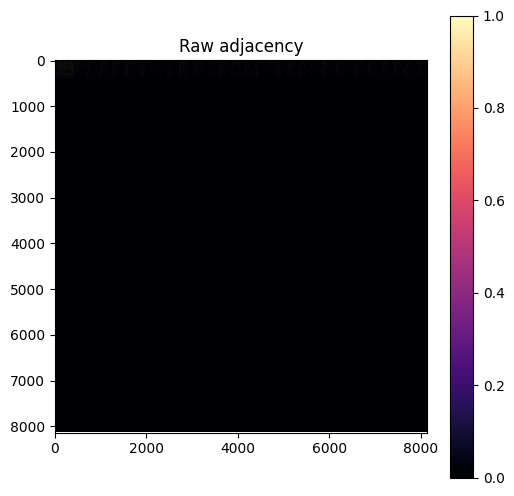

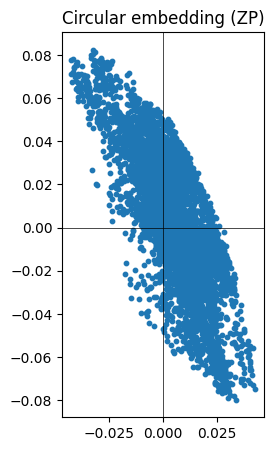

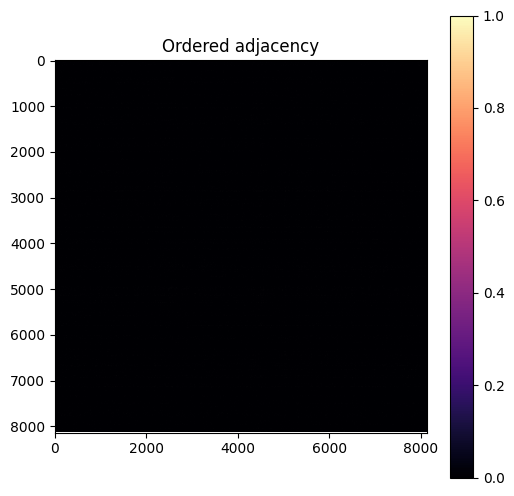

In [41]:
plot_adjacency(W_active, title="Raw adjacency")
plot_projected(Y)
plot_adjacency(W_active, perm=perm, title="Ordered adjacency")

In [42]:
import numpy as np

def circularity_index(Z, perm, P):

    # --------------------------------------------------
    # 1. cible cercle
    # --------------------------------------------------
    M = Z.shape[0]
    theta = np.linspace(0, 2*np.pi, M, endpoint=False)
    T = np.stack([np.cos(theta), np.sin(theta)], axis=1)

    # --------------------------------------------------
    # 2. embeddings projetés
    # --------------------------------------------------
    Z_perm = Z[perm]
    Y = Z_perm @ P

    # --------------------------------------------------
    # 3. erreur quadratique
    # --------------------------------------------------
    num = np.linalg.norm(T - Y)**2
    den = np.linalg.norm(T)**2

    r2_circ = 1 - num / den

    return r2_circ

In [45]:
print(circularity_index(Z_active,perm,P))

0.0009007698048797419
